# Spatial Search on 4D quantum walk

Flip-flop coined quantum walk on the $4$-dimensional periodic hypercubic lattice with $N = x^4$ nodes.

The coin register has $k = 2d = 8$ states: $|0\rangle: -x$, $|1\rangle: +x$, $|2\rangle: -y$, $|3\rangle: +y$, $|4\rangle: -z$, $|5\rangle: +z$, $|6\rangle: -w$, $|7\rangle: +w$.

The shift moves the walker according to the coin state, and then flips the coin $|2i\rangle \leftrightarrow |2i+1\rangle$ by applying $X$ to the least significant coin qubit (flip-flop walk).

In [1]:
#import classiq 
#classiq.authenticate()

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from classiq import *
import time

/Users/reisato/PycharmProjects/pythonProject1/.venv/lib/python3.11/site-packages/classiq/__init__.py:109: UserWarning: 'nest_asyncio2' is not installed; falling back to the legacy 'nest_asyncio'. 'nest_asyncio2' ships with modern Jupyter (ipykernel >= 7.3); consider upgrading your Jupyter installation, for example: pip install --upgrade jupyter ipykernel
  enable_jupyter_notebook()


In [3]:
d = 4
q = 3
x_piece = 2**q
N = x_piece ** d

k = 2*d
nx = int(np.ceil(np.log2(x_piece)))
nl = int(np.ceil(np.log2(k)))
NUM_SAMPLES = 1000
print("N =",N , "nx =", nx, "nl =", nl )

N = 4096 nx = 3 nl = 3


In [4]:
class pos_reg(QStruct):
    x: QNum[nx]
    y: QNum[nx]
    z: QNum[nx]
    w: QNum[nx]

@qfunc
def prepare_pos_state(pos: pos_reg):
    if x_piece == (2**nx):
        hadamard_transform(pos)
    else:
        prob_array = np.ones(2**nx)/x_piece
        prob_array[x_piece:2**(nx)] = 0
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.x)
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.y)
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.z)
        inplace_prepare_state(prob_array.tolist(), 0.0, pos.w)

@qfunc 
def prepare_coin_state(l:QNum[nl]):
    if k == 2**nl:
        hadamard_transform(l)
    elif k < 2**nl:
        prob_list = [1/k]*k + [0]*(2**nl - k)
        inplace_prepare_state(prob_list, 0.0, l)

@qfunc 
def initial_state(pos: pos_reg, l:QNum):
    prepare_pos_state(pos)
    prepare_coin_state(l)

@qperm
def oracle_operator(pos: pos_reg):
    control(((pos.x == x_piece//2) & (pos.y == x_piece//2) & (pos.z == x_piece//2) & (pos.w == x_piece//2)), lambda: phase(np.pi))


@qfunc
def coin_opeator(l: QNum):
    grover_diffuser(lambda psi: prepare_coin_state(psi), l)

@qfunc
def shift_plus(p: QNum):
    p += 1 

@qfunc
def shift_minus(p: QNum):
    p += -1

@qfunc 
def move_opeartor(pos: pos_reg, l:QNum):
    control(l == 0, lambda: shift_minus(pos.x))
    control(l == 1, lambda: shift_plus(pos.x))
    control(l == 2, lambda: shift_minus(pos.y))
    control(l == 3, lambda: shift_plus(pos.y))
    control(l == 4, lambda: shift_minus(pos.z))
    control(l == 5, lambda: shift_plus(pos.z))
    control(l == 6, lambda: shift_minus(pos.w))
    control(l == 7, lambda: shift_plus(pos.w))

@qfunc 
def flip_operator(l:QArray):
    X(l[0])

@qfunc 
def shift_opeartor(pos: pos_reg, l:QNum):
    move_opeartor(pos, l)
    flip_operator(l)

@qfunc 
def quantum_walk(pos: pos_reg, l:QNum):
    coin_opeator(l)
    shift_opeartor(pos, l)

@qfunc 
def coin_walk(t: CInt, pos: pos_reg, l:QNum):
    power(
        t,
        lambda: [oracle_operator(pos),quantum_walk(pos, l)],
    )

@qfunc
def main(t: CInt, p: Output[pos_reg]):
    l = QNum()
    allocate(p.size,p)
    allocate(nl,l)
    initial_state(p,l)
    coin_walk(t, p, l)
    drop(l)

In [5]:
qprog = synthesize(main)
print("width =", qprog.data.width)
#show(qprog)

width = 16


# Exact simulation (reference)
Same as `d>3/exact_sim_d4.ipynb`.

In [6]:
def exact_mark_prob(d, N_side, itr):
    n_coin = 2 * d
    mark = (N_side // 2,) * d
    C = np.ones((n_coin, n_coin)) * (2.0 / n_coin) - np.eye(n_coin)
    psi = np.ones((N_side,) * d + (n_coin,), dtype=float) / np.sqrt(N_side ** d * n_coin)
    mark_prob = []
    for t in range(itr):
        if t > 0:
            psi[mark] *= -1
            psi_coin = psi @ C.T
            next_psi = np.zeros_like(psi)
            for i in range(d):
                next_psi[..., 2 * i + 1] = np.roll(psi_coin[..., 2 * i], +1, axis=i)
                next_psi[..., 2 * i] = np.roll(psi_coin[..., 2 * i + 1], -1, axis=i)
            psi = next_psi
        mark_prob.append(np.sum(psi[mark] ** 2))
    return mark_prob

itr = 200
time_steps = list(range(itr))
mark_prob = exact_mark_prob(d, x_piece, itr)
print(f"Peak probability: {max(mark_prob):.4f} at t={mark_prob.index(max(mark_prob))}")

Peak probability: 0.4078 at t=81


# Circuit simulation

In [7]:
t_list = [20, 40, 60, 80, 100, 120, 140, 160]
circuit_prob = []

exec_pref = ExecutionPreferences(num_shots=NUM_SAMPLES)
with ExecutionSession(qprog, execution_preferences=exec_pref) as es:
    for t in t_list:
        df = es.sample({"t": t}).dataframe
        circuit_prob.append(df.loc[(df["p.x"] == x_piece//2) & (df["p.y"] == x_piece//2) & (df["p.z"] == x_piece//2) & (df["p.w"] == x_piece//2), "probability"].sum())
        print(f"t={t}: P(x0)={circuit_prob[-1]:.3f}")

t=20: P(x0)=0.065


t=40: P(x0)=0.190


t=60: P(x0)=0.360


t=80: P(x0)=0.376


t=100: P(x0)=0.331


t=120: P(x0)=0.177


t=140: P(x0)=0.046


t=160: P(x0)=0.002


In [8]:
import pandas as pd

exact_at_t = [mark_prob[t] for t in t_list]
shot_err = [np.sqrt(p * (1 - p) / NUM_SAMPLES) for p in exact_at_t]
comparison = pd.DataFrame({
    "t": t_list,
    "exact": exact_at_t,
    "circuit": circuit_prob,
    "abs_diff": np.abs(np.array(circuit_prob) - np.array(exact_at_t)),
    "shot_noise_1sigma": shot_err,
})
comparison

,t,exact,circuit,abs_diff,shot_noise_1sigma
0,20,0.068053,0.065,0.003053,0.007964
1,40,0.217964,0.190,0.027964,0.013056
2,60,0.360271,0.360,0.000271,0.015181
3,80,0.407838,0.376,0.031838,0.015540
4,100,0.332509,0.331,0.001509,0.014898
5,120,0.179330,0.177,0.002330,0.012131
6,140,0.041290,0.046,0.004710,0.006292
7,160,0.002281,0.002,0.000281,0.001509


In [9]:
plt.rcParams.update({
    "font.size": 20,
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 1.2,
})

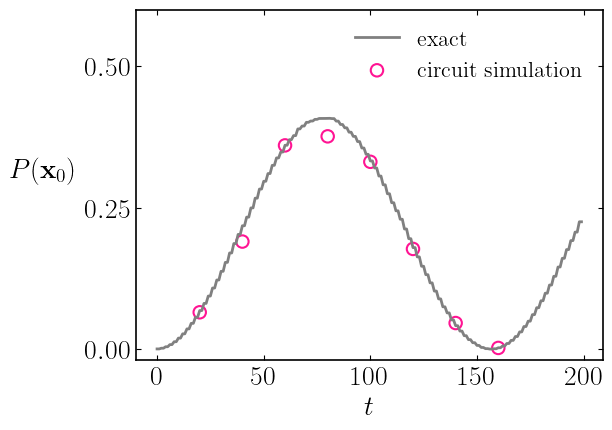

In [10]:
plt.plot(time_steps, mark_prob, linewidth=2.0, color="gray", label=r"$\rm exact$")
plt.scatter(t_list, circuit_prob,
            facecolors='none',
            edgecolors='deeppink',
            linewidths=1.5,
            s=80,
            label="circuit simulation")
plt.legend(loc="upper right", fontsize=16, frameon=False)
plt.ylim([-0.02, 0.6])
plt.xlabel(r"$t$")
plt.ylabel(r"$P({\bf x}_0)$", rotation=0, labelpad=30)
plt.tick_params(which="both",
        top=True, bottom=True, left=True, right=True,
        direction="in")
plt.tight_layout()
plt.yticks([0.0, 0.25, 0.5])
plt.savefig("ss_search_d4_circuit.png")
plt.show()

## Reference

https://arxiv.org/pdf/1010.4705